# RGB by Pasting Canonical Objects

Turn a trained mask model's predictions into photos: take the empty box and paste a **canonical image** of each object at the **predicted
centre of mass**. No new training, no rotation. Set `RUN` and `SPEAKER` as env variables (or edit the defaults below).

In [1]:
import os, sys, itertools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from PIL import Image
from sklearn.cluster import KMeans

RUN = os.environ.get("RUN", "s6-box-plastic-allspk-v1")
SPEAKER = os.environ.get("SPEAKER", "all")  # e.g. 1; 'all' = every speaker
EPOCH = 2000
SCALE = 0.25        # work at 1/4 of the cropped photo (1010x1311 -> 252x328)
R = round(130 * SCALE)  # canonical crops are (2R+1)^2 around the object's centre
N_SHOW = 5

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO / "src6"))
from dataset import EXPERIMENTS, DATASETS, collect_samples, build_splits

cfg = {k: v["value"] for k, v in yaml.safe_load(sorted(REPO.glob(f"wandb/run-*-{RUN}/files/config.yaml"))[-1].read_text()).items() if isinstance(v, dict)}
splits = DATASETS[cfg["dataset"]](cfg["test_size"], None if "all" in cfg["speakers"] else cfg["speakers"])  # the run's own split
samples = {d: m for e in sorted({s["experiment"] for s in splits.values()}) for d, m in collect_samples(EXPERIMENTS / e).items()}
dirs, metas = list(samples), list(samples.values())
idxs = build_splits(splits, metas)
print(RUN, cfg["dataset"], "speakers", cfg["speakers"])


collecting 2026_10_05_green_plastic_four_objs:   0%|          | 0/5736 [00:00<?, ?it/s]


collecting 2026_10_05_green_plastic_four_objs:  13%|█▎        | 735/5736 [00:00<00:02, 2191.07it/s]


collecting 2026_10_05_green_plastic_four_objs:  28%|██▊       | 1593/5736 [00:00<00:01, 4098.82it/s]


collecting 2026_10_05_green_plastic_four_objs:  38%|███▊      | 2188/5736 [00:00<00:01, 2672.40it/s]


collecting 2026_10_05_green_plastic_four_objs:  51%|█████     | 2937/5736 [00:01<00:01, 2267.63it/s]


collecting 2026_10_05_green_plastic_four_objs:  66%|██████▌   | 3779/5736 [00:01<00:00, 3189.48it/s]


collecting 2026_10_05_green_plastic_four_objs:  78%|███████▊  | 4452/5736 [00:01<00:00, 2413.06it/s]


collecting 2026_10_05_green_plastic_four_objs:  92%|█████████▏| 5303/5736 [00:01<00:00, 3251.06it/s]


collecting 2026_10_05_green_plastic_four_objs: 100%|██████████| 5736/5736 [00:01<00:00, 3073.68it/s]

2026_10_05_green_plastic_four_objs: 5736 samples, skipped 0 incomplete: []
s6-box-plastic-allspk-v1 plastic speakers ['all']


Helpers: everything is at `SCALE`, coms are (row, col). The background of each box is the mean of its train empty-box photos.

In [2]:
def size(i): return tuple(round(s * SCALE) for s in metas[i]["crop_overhead_shape"][:2])  # (H,W)
def photo(i): return np.asarray(Image.open(dirs[i] / "image/02_cropped_overhead.png").convert("RGB").resize(size(i)[::-1], Image.BOX), np.float32) / 255
def mask(i, hw=None): return np.asarray(Image.open(dirs[i] / "image/03_smask.png").convert("F").resize((hw or size(i))[::-1], Image.BOX), np.float32) / 255
def coms(i): return np.array([c[0] for c in metas[i]["coms"]]) * SCALE   # (K,2), same order as metas[i]["objects"]
def crop(img, c): r, c = np.round(c).astype(int); return np.pad(img, [(R, R), (R, R)] + [(0, 0)] * (img.ndim - 2))[r:r + 2 * R + 1, c:c + 2 * R + 1]
def iou(a, b): return np.minimum(a, b).sum() / max(np.maximum(a, b).sum(), 1e-6)
def psnr(a, b, region=None): return -10 * np.log10(((a - b) ** 2)[region if region is not None else ...].mean())

def paste(bg, objs):
    """bg with each (rgb, alpha) canonical crop centred on its com"""
    out = np.pad(bg, [(R, R), (R, R), (0, 0)])
    for (rgb, a), c in objs:
        r, c = np.clip(np.round(c).astype(int), 0, np.array(bg.shape[:2]) - 1)
        win = out[r:r + 2 * R + 1, c:c + 2 * R + 1]
        win[:] = win * (1 - a[..., None]) + rgb * a[..., None]
    return out[R:-R, R:-R]

train = idxs["train"]
BG = {e: np.mean([photo(i) for i in train if metas[i]["experiment"] == e and metas[i]["n_objects"] == 0], 0) for e in {m["experiment"] for m in metas}}

# 1 Canonical Image per Object

For each object (per box), every train sample with it, one per position. Its area is the mask inside the crop around that object's com.
The canonical image is the sample at the **10th percentile of area**: small (seen most nearly straight down) but not the outlier at the very bottom.
Objects that never appear in train (only in eval-only splits) fall back to all samples; those are marked *eval*.

,box,object,source,n,area,area_min,area_max,sample
0,green_plastic_four_objs,candle,train,202,2454.783203,2328.000000,2836.641602,001974-7
1,green_plastic_four_objs,coffee pot,eval,86,1519.237549,1446.900024,1626.062500,001897-7
2,green_plastic_four_objs,cylinder,eval,32,76.312500,61.625000,530.125000,001798-7
3,green_plastic_four_objs,green-cube,train,64,679.312500,654.937500,752.562500,002764-7
4,green_plastic_four_objs,portable-charger,eval,10,1877.937500,1841.687500,1949.312500,002872-7
5,green_plastic_four_objs,red-cube,train,337,701.974976,672.312500,789.604187,002545-7
6,green_plastic_four_objs,soap dispenser,train,237,1117.875000,1095.612549,1602.562500,001565-7
7,green_plastic_four_objs,vase,train,244,1533.437500,1494.500000,1695.437500,002808-7


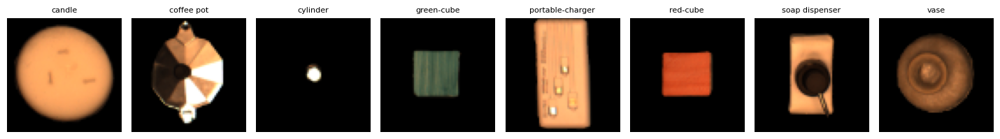

In [3]:
CANON, rows = {}, []
for e, o in sorted({(m["experiment"], o) for m in metas for o in m["objects"]}):
    has = lambda i: metas[i]["experiment"] == e and o in metas[i]["objects"]
    pool, src = [i for i in train if has(i)], "train"
    if not pool: pool, src = [i for i in range(len(metas)) if has(i)], "eval"
    pool = list({metas[i]["position_id"]: i for i in pool}.values())  # one per position
    k = lambda i: list(metas[i]["objects"]).index(o)
    areas = np.array([crop(mask(i), coms(i)[k(i)]).sum() for i in pool])
    j = np.argsort(areas)[int(0.1 * len(pool))]
    i = pool[j]
    CANON[e, o] = crop(photo(i), coms(i)[k(i)]), crop(mask(i), coms(i)[k(i)])
    rows.append(dict(box=e[11:], object=o, source=src, n=len(pool), area=areas[j], area_min=areas.min(), area_max=areas.max(), sample=dirs[i].name))
display(pd.DataFrame(rows))

fig, axs = plt.subplots(1, len(CANON), figsize=(1.8 * len(CANON), 2.2), squeeze=False)
for ax, ((e, o), (rgb, a)) in zip(axs[0], CANON.items()):
    ax.imshow(rgb * a[..., None]); ax.set_title(o, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

# 2 Best and Worst Samples per Eval Split

Every eval sample is scored first (of `SPEAKER`). Then, per split, the **2 best and 2 worst by com distance** are shown:
**predicted vs true mask** (IoU), **predicted vs true com** (x = predicted, + = true, distance as a fraction of the box, like the run's `com_err`),
and the **canonical objects pasted at the predicted coms vs the true photo** (PSNR).

Predicted coms: k-means on the predicted mask's pixels (p > 0.5, weighted by p), with k = the true number of objects. With two objects,
each predicted com is paired with the true object it best matches, so which object goes where is taken from the truth.

In [4]:
preds = {}
for f in sorted((REPO / f"runs/{RUN}/outputs_history/eval").rglob(f"ep{EPOCH:04d}-*.pt")):
    d = torch.load(f, weights_only=False)
    for p, e, pos, spk in zip(d["mask_pred"], d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()): preds[e, pos, spk] = p.float()

def pred_coms(P, k):
    """k-means on the predicted mask's pixels -> (k,2) coms"""
    px = np.argwhere(P > 0.5) if (P > 0.5).sum() >= k else np.argwhere(P >= np.sort(P.ravel())[-50])  # nothing confident: the top 50 pixels
    return KMeans(k, n_init=4, random_state=0).fit(px, sample_weight=P[tuple(px.T)]).cluster_centers_

def evaluate(i):
    m, H, W = metas[i], *size(i)
    p64 = preds[m["experiment"], m["position_id"], m["speaker"]]
    P = F.interpolate(p64[None, None], (H, W), mode="bilinear")[0, 0].numpy()
    gc, k = coms(i), len(m["objects"])
    pc = pred_coms(P, k)
    pc = pc[list(min(itertools.permutations(range(k)), key=lambda o: np.linalg.norm(pc[list(o)] - gc, axis=1).sum()))]  # pair with the true objects
    canon = [CANON[m["experiment"], o] for o in m["objects"]]
    return dict(p64=p64, P=P, M=mask(i), Y=photo(i), gc=gc, pc=pc, com_err=np.linalg.norm((pc - gc) / [H, W], axis=1).mean(),
                pasted=paste(BG[m["experiment"]], zip(canon, pc)), pasted_true_com=paste(BG[m["experiment"]], zip(canon, gc)))

# nearest train sample (section 3): the train photo with the same box and objects whose mask best matches the predicted one
pool = list({(metas[i]["experiment"], metas[i]["position_id"]): i for i in train if metas[i]["n_objects"] > 0}.values())
T64 = np.stack([mask(i, (64, 64)) for i in pool])  # (N,64,64)
def nearest(i, p64):
    m = metas[i]
    same = [j for j, t in enumerate(pool) if metas[t]["experiment"] == m["experiment"] and metas[t]["objects"].keys() == m["objects"].keys()]
    same = same or [j for j, t in enumerate(pool) if metas[t]["experiment"] == m["experiment"]]
    t = pool[same[np.argmax([iou(p64.numpy(), T64[j]) for j in same])]]
    a = mask(t)[..., None]
    return BG[m["experiment"]] * (1 - a) + photo(t) * a

EVAL = {name[5:]: [i for i in ids if SPEAKER == "all" or metas[i]["speaker"] == int(SPEAKER)] for name, ids in idxs.items() if name != "train"}

rows = []
for split, ids in EVAL.items():
    for i in ids:
        s = evaluate(i)
        obj = s["M"] > 0.5
        outs = {"pasted @ pred com": s["pasted"], "pasted @ true com": s["pasted_true_com"], "nearest train": nearest(i, s["p64"]), "empty box": BG[metas[i]["experiment"]]}
        for method, img in outs.items():
            rows.append(dict(split=split, i=i, method=method, iou=iou(s["P"], s["M"]), com_err=s["com_err"], psnr=psnr(img, s["Y"]), obj_psnr=psnr(img, s["Y"], obj)))
df = pd.DataFrame(rows)
print({k: len(v) for k, v in EVAL.items()})

{'plastic/soap-dispenser': 234, 'plastic/vase': 204, 'plastic/candle': 204, 'plastic/cube': 200, 'plastic/coffee-pot': 344, 'plastic/two-cubes': 64, 'plastic/cube-vase': 40, 'plastic/cube-lid': 64, 'plastic/portable-charger': 50, 'plastic/cylinder-200g': 36, 'plastic/soap-dispenser-sideways': 28, 'plastic/cylinder-100g': 28, 'plastic/cylinder-500g': 32, 'plastic/cylinder-1000g': 32, 'plastic/cube-shifted-lasers-1': 40, 'plastic/cube-shifted-lasers-2': 40, 'plastic/cube-shifted-lasers-3-backside': 40, 'plastic/cube-5-speakers': 40}


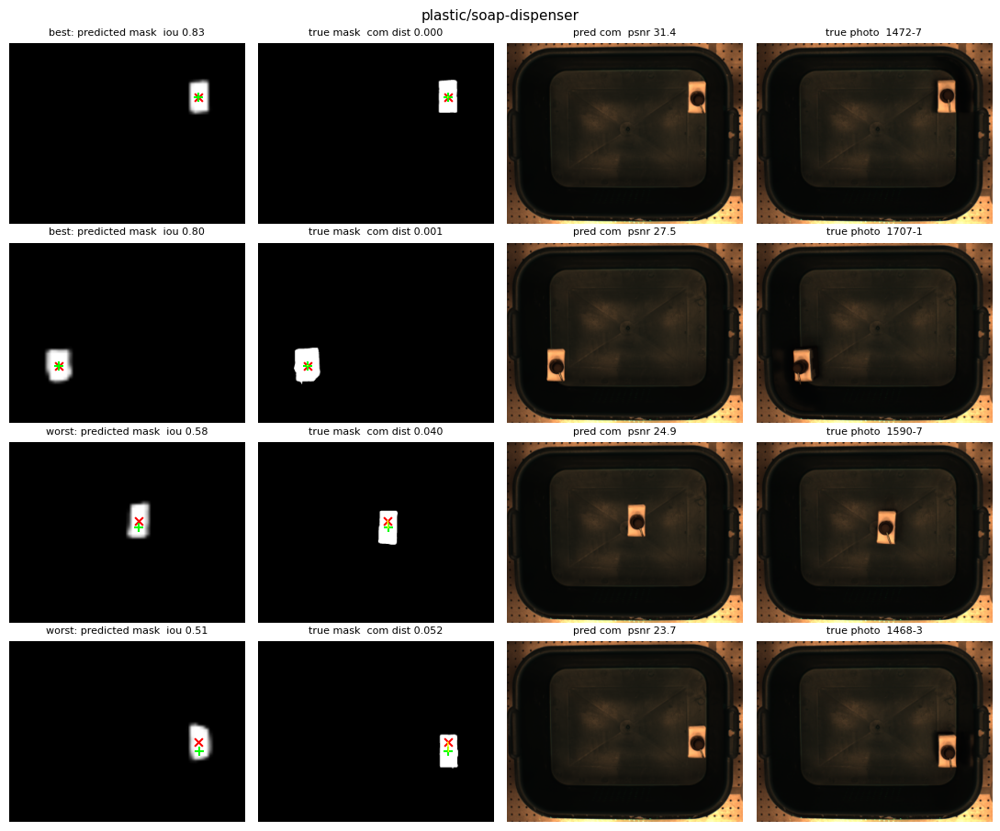

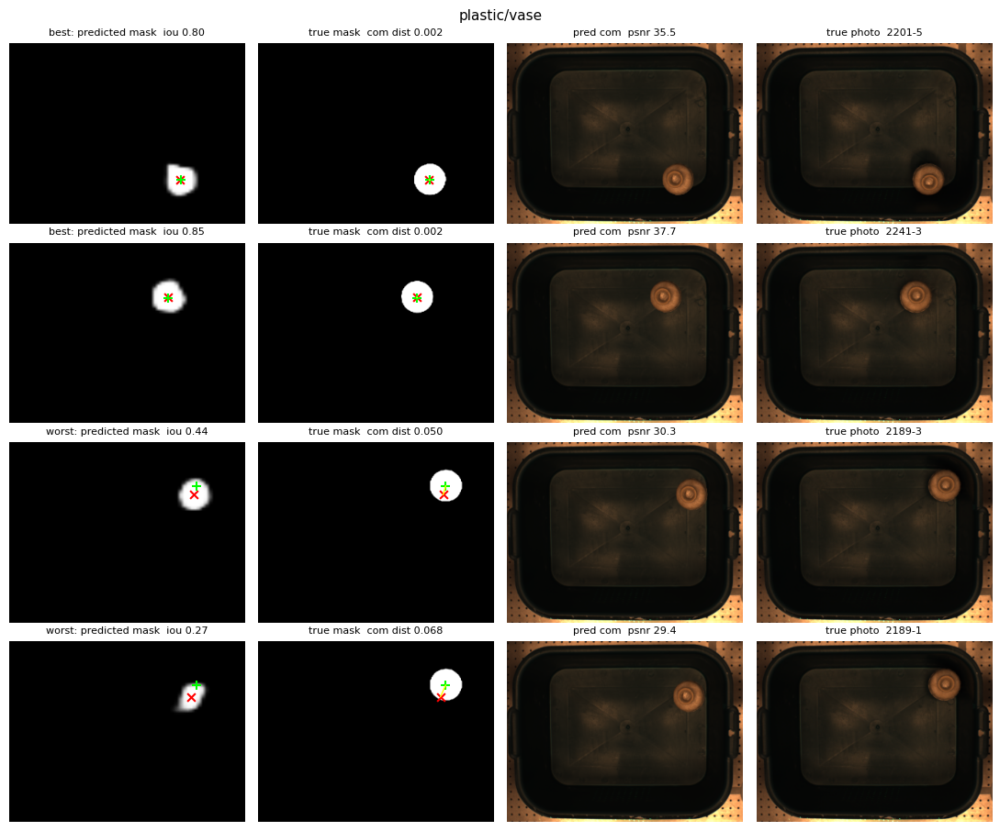

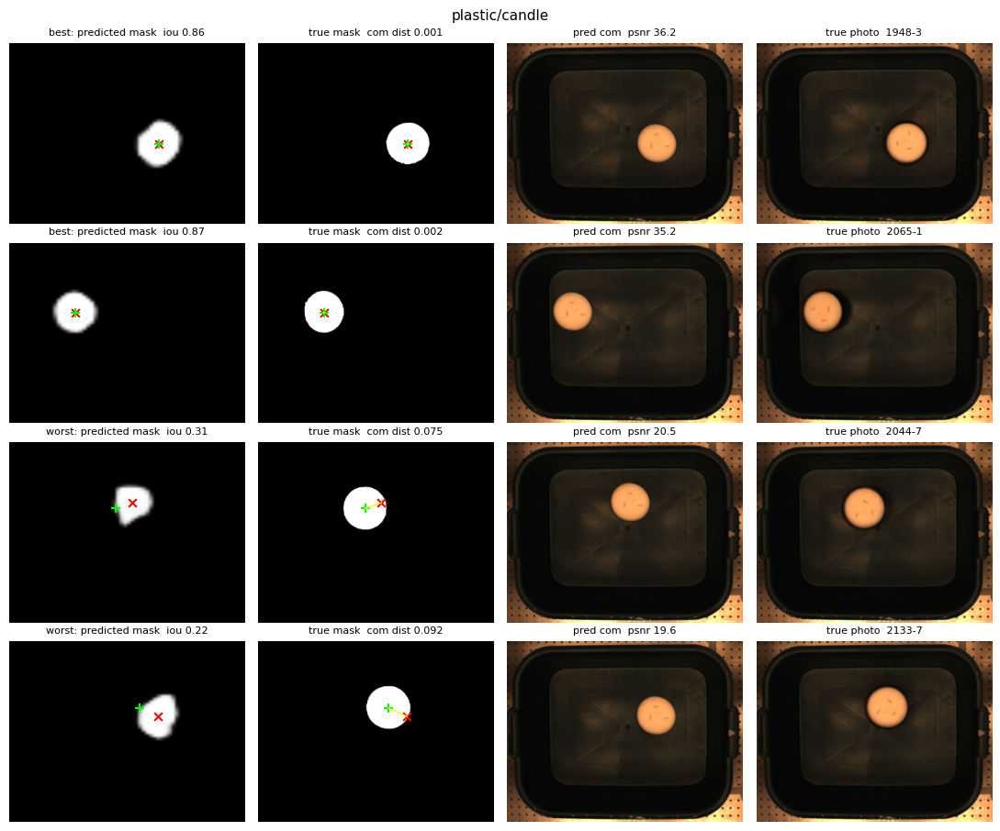

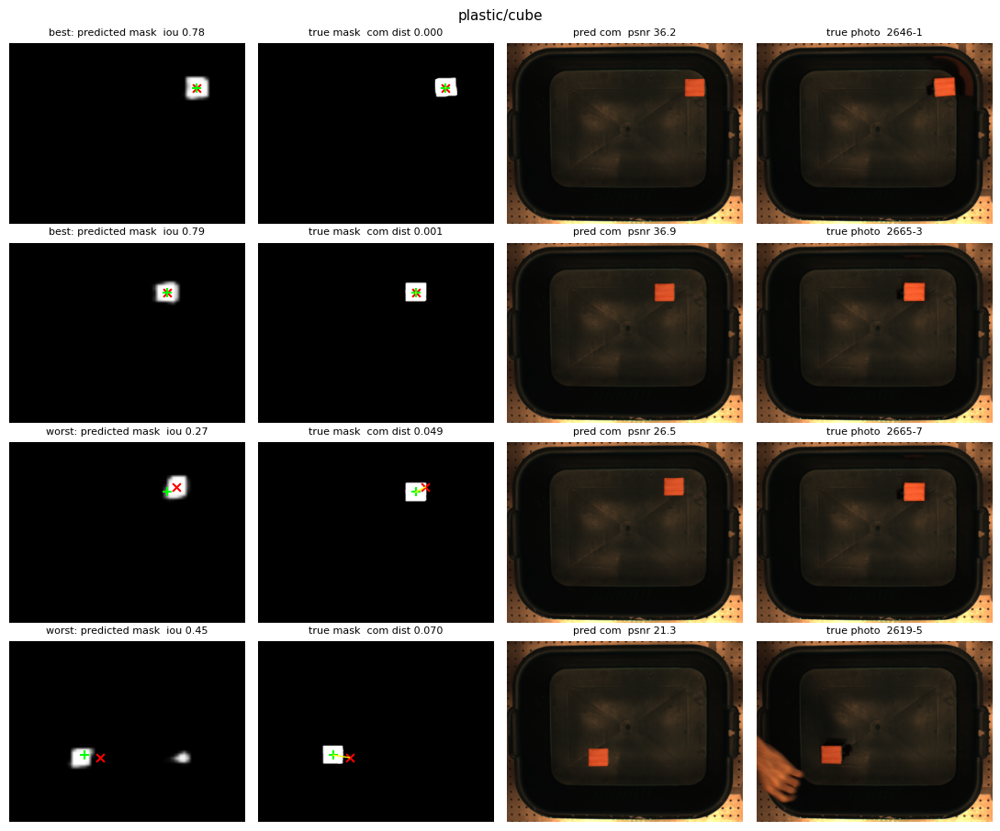

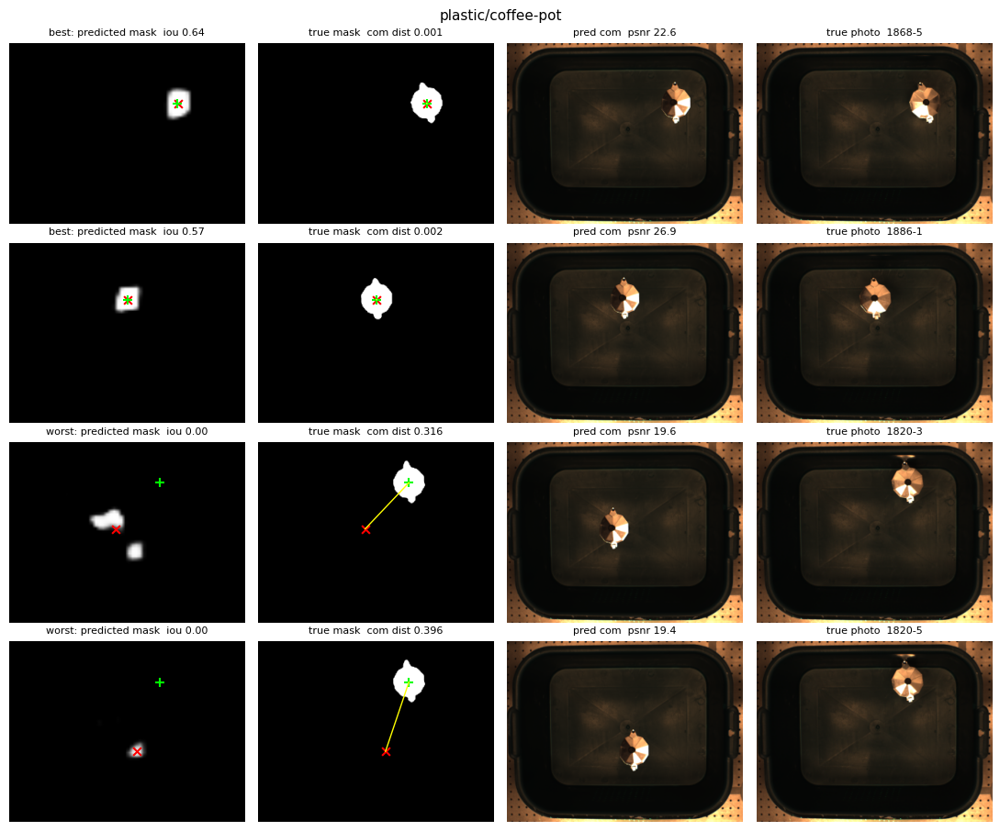

...

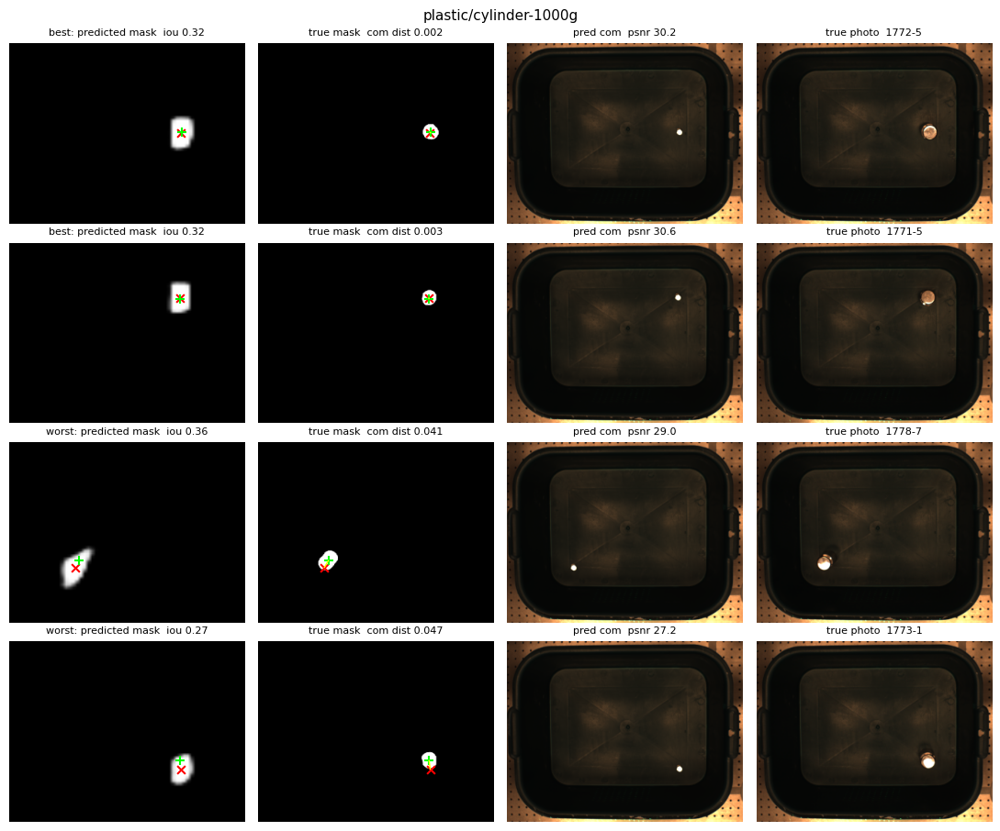

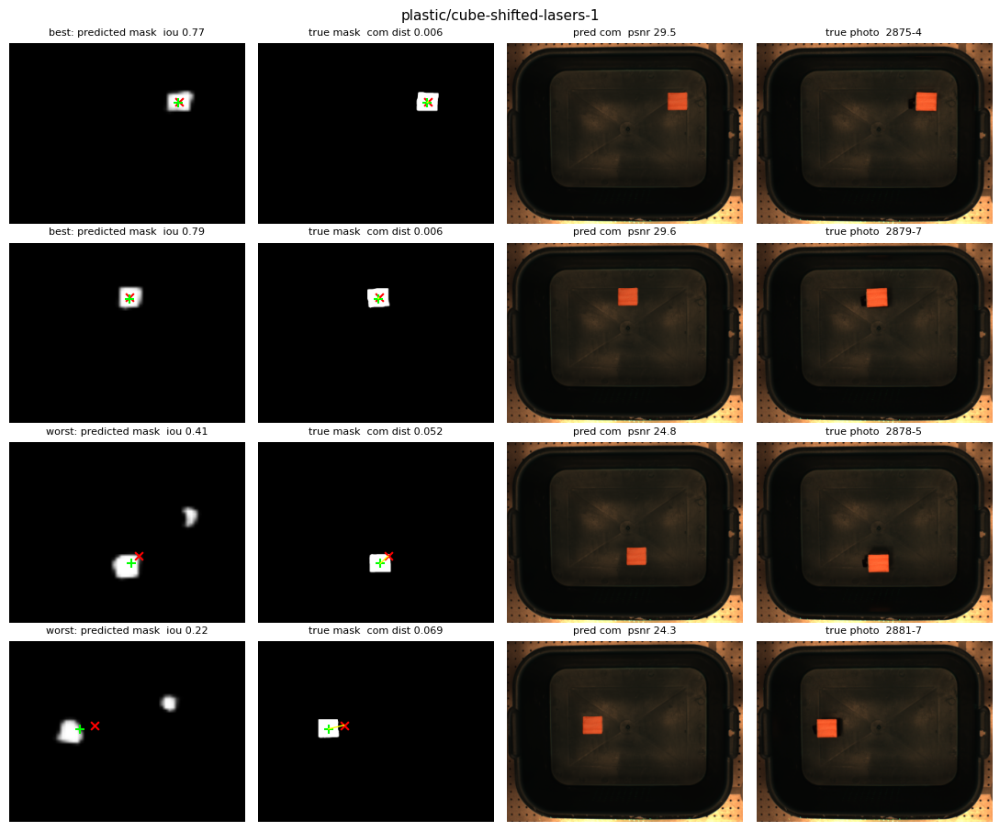

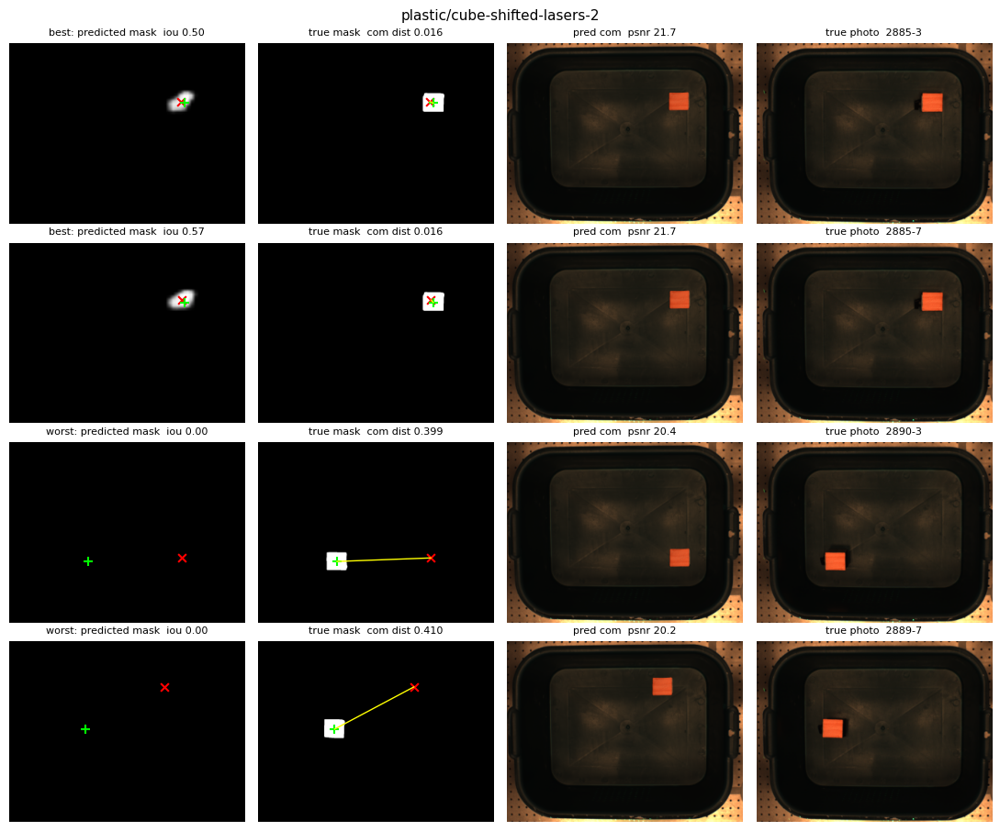

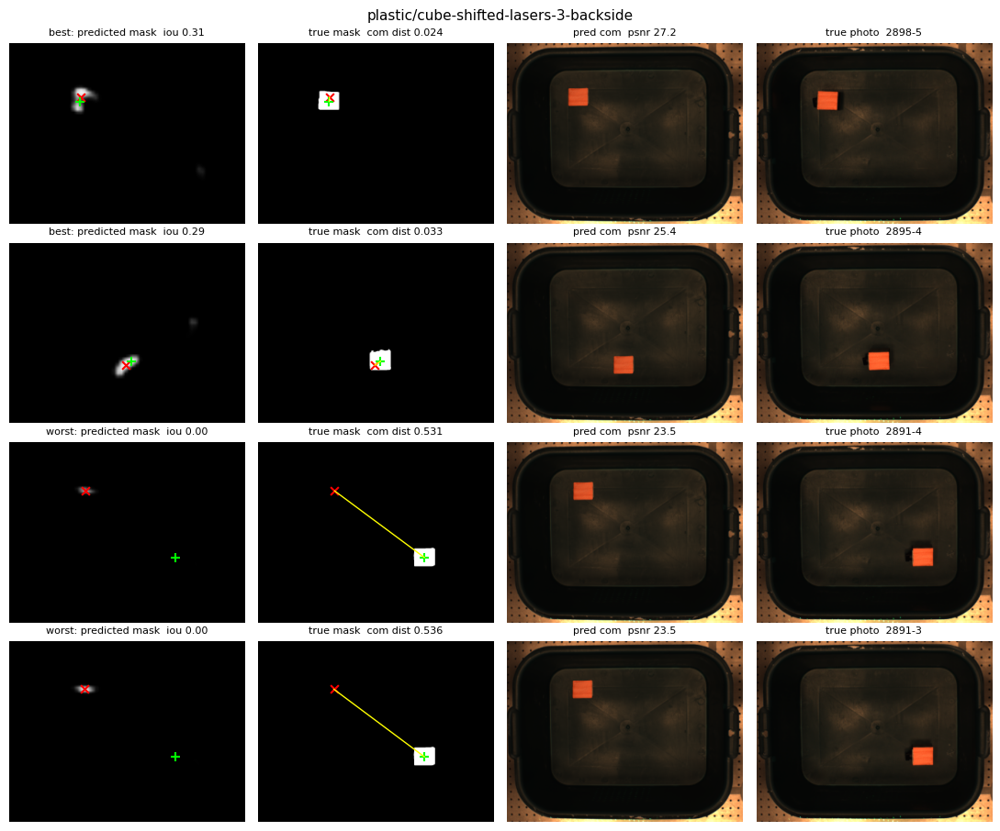

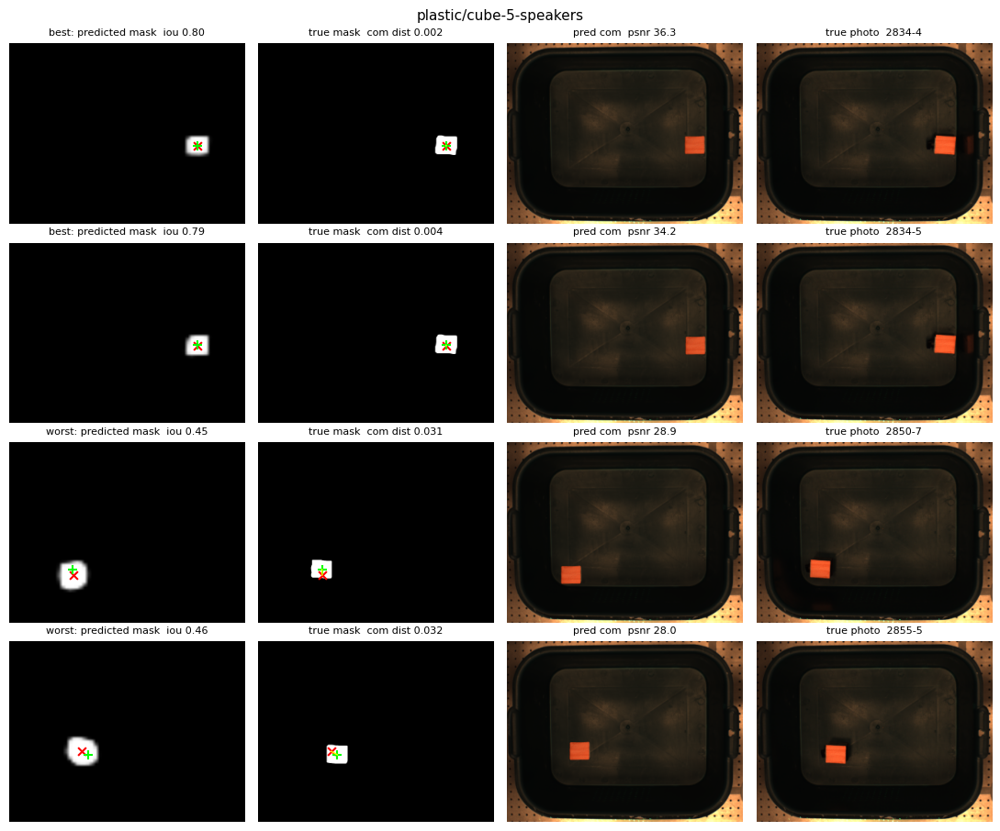

In [5]:
def best_worst(split, n=2):
    """the split's n best and n worst samples by com distance"""
    d = df[(df.split == split) & (df.method == "pasted @ pred com")].sort_values("com_err")
    return [*d.i[:n], *d.i[-n:]]

def gallery(split, pred_class=False):
    ids = best_worst(split)
    cols = 5 if pred_class else 4
    fig, axs = plt.subplots(len(ids), cols, figsize=(2.75 * cols, 2.3 * len(ids)), squeeze=False)
    for n, (row, i) in enumerate(zip(axs, ids)):
        s, true_cls = evaluate(i), "+".join(sorted(metas[i]["objects"]))
        imgs = [s["P"], s["M"], s["pasted"], s["Y"]]
        if pred_class: imgs.insert(2, paste_pred_class(i, s))
        for ax, img in zip(row, imgs): ax.imshow(img, cmap="gray", vmin=0, vmax=1); ax.axis("off")
        for ax in row[:2]:
            ax.scatter(s["pc"][:, 1], s["pc"][:, 0], marker="x", c="red", s=40); ax.scatter(s["gc"][:, 1], s["gc"][:, 0], marker="+", c="lime", s=60)
        for (r0, c0), (r1, c1) in zip(s["pc"], s["gc"]): row[1].plot([c0, c1], [r0, r1], c="yellow", lw=1)
        tag = "best" if n < 2 else "worst"
        row[0].set_title(f"{tag}: predicted mask  iou {iou(s['P'], s['M']):.2f}" + (f"\npredicted class: {CLASS[i] or 'empty'}" if pred_class else ""), fontsize=8)
        row[1].set_title(f"true mask  com dist {s['com_err']:.3f}" + (f"\ntrue class: {true_cls}" if pred_class else ""), fontsize=8)
        if pred_class: row[2].set_title(f"pred com + pred class  psnr {psnr(imgs[2], s['Y']):.1f}", fontsize=8)
        row[-2].set_title(f"pred com{' + true class' if pred_class else ''}  psnr {psnr(s['pasted'], s['Y']):.1f}", fontsize=8)
        row[-1].set_title(f"true photo  {metas[i]['position_id']}-{metas[i]['speaker']}", fontsize=8)
    fig.suptitle(split, fontsize=11); plt.tight_layout(); plt.show()

for split in EVAL: gallery(split)

# 3 Comparisons, Every Eval Sample

Per eval split, the mean over every sample of:

- **pasted @ pred com**: section 2's method.
- **pasted @ true com**: the canonical images at the true coms, the ceiling of pasting with perfect sensing.
- **nearest train**: the train photo (same box, same objects when train has them) whose mask best matches the predicted mask (IoU at 64x64), pasted inside its own mask.
- **empty box**: nothing pasted, the floor.

`psnr` is the whole photo, which is mostly the constant background; `obj_psnr` is only over the true object's pixels.

In [6]:
df.groupby(["split"], sort=False)[["iou", "com_err"]].mean().join(df.pivot_table(index="split", columns="method", values="obj_psnr", sort=False).add_prefix("obj_psnr | ")).round(3)

,iou,com_err,obj_psnr | pasted @ pred com,obj_psnr | pasted @ true com,obj_psnr | nearest train,obj_psnr | empty box
split,,,,,,
plastic/soap-dispenser,0.718,0.013,11.032,13.240000,11.745,8.285
plastic/vase,0.743,0.013,19.975,21.438000,17.862,13.433
plastic/candle,0.706,0.022,15.290,23.111000,15.510,6.025
plastic/cube,0.623,0.016,13.973,19.614000,14.069,6.757
plastic/coffee-pot,0.522,0.027,7.553,8.623000,7.727,6.267
plastic/two-cubes,0.345,0.079,11.792,20.410999,9.508,8.700
plastic/cube-vase,0.311,0.063,13.974,20.625000,11.430,9.961
plastic/cube-lid,0.295,0.112,15.477,16.283001,15.387,12.526
plastic/portable-charger,0.348,0.043,10.233,21.889999,6.174,4.922


In [7]:
df.pivot_table(index="split", columns="method", values="psnr", sort=False).add_prefix("psnr | ").round(2)

method,psnr | pasted @ pred com,psnr | pasted @ true com,psnr | nearest train,psnr | empty box
split,,,,
plastic/soap-dispenser,28.170000,30.660000,28.490000,26.280001
plastic/vase,34.040001,35.360001,31.790001,29.740000
plastic/candle,28.690001,35.860001,28.240000,20.889999
plastic/cube,31.719999,36.389999,30.730000,26.860001
plastic/coffee-pot,23.379999,25.230000,24.360001,23.370001
plastic/two-cubes,27.110001,35.200001,24.610001,26.100000
plastic/cube-vase,27.299999,34.270000,24.120001,25.360001
plastic/cube-lid,23.670000,25.379999,23.370001,21.700001
plastic/portable-charger,24.270000,35.740002,22.200001,21.260000


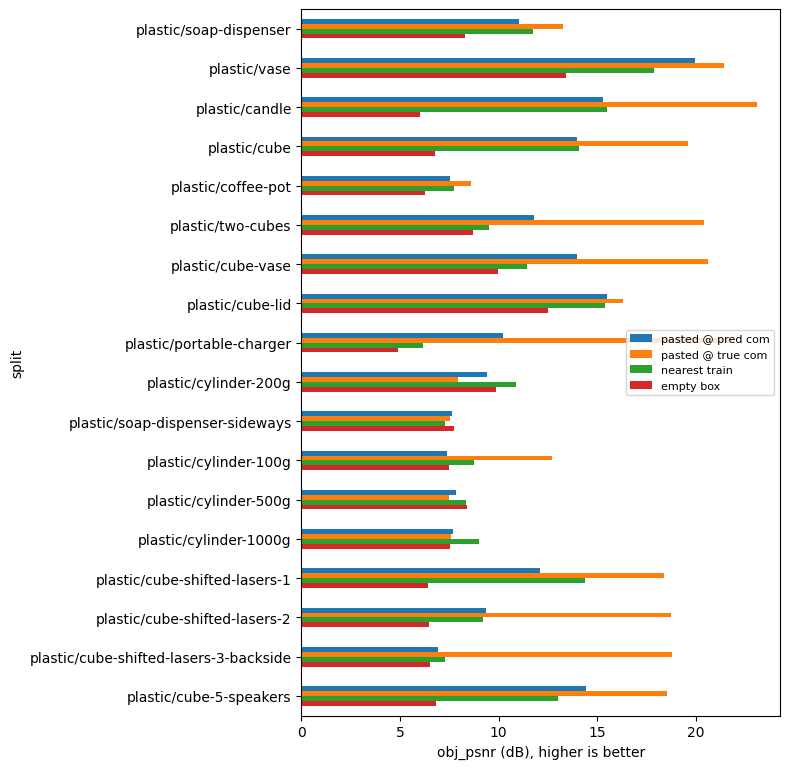

In [8]:
t = df.pivot_table(index="split", columns="method", values="obj_psnr", sort=False)
t.plot.barh(figsize=(8, 0.35 * len(t) + 1.5)); plt.xlabel("obj_psnr (dB), higher is better"); plt.gca().invert_yaxis(); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

# 4 Predicted Object Class

Sections 2-3 used the **true** objects and only predicted where they are. Here the objects come from the model too: the run's object head
(one class per object combination seen in train, e.g. `green-cube+red-cube`). The run only saved masks, so the checkpoint is re-run on the
eval samples, and its masks are checked against the saved ones.

With predicted objects: if the predicted objects are the true ones, the paste is section 2's. Otherwise the predicted objects are pasted at
k-means coms of the predicted mask (k = number of predicted objects), in no particular order. Objects never seen in train (coffee pot,
cylinder, portable charger) have no class, so they are always pasted as something else.

In [9]:
from arch import Boombox
from dataset import get_data_info, process_x

info = get_data_info(samples, train)  # the class list the run trained with
model = Boombox(cfg["d_model"], info, cfg["out_h"], cfg["out_w"])
missing = model.load_state_dict(torch.load(next((REPO / f"runs/{RUN}/checkpoints").glob(f"ep{EPOCH}-*.pt")), weights_only=False)["state"]["model"], strict=False)
assert all(k.startswith("box_head") for k in missing.missing_keys) and not missing.unexpected_keys, missing  # src6 added a box head after this run
model = model.cuda().eval()

ids = sorted({i for v in EVAL.values() for i in v})
CLASS, diff = {}, []
with torch.no_grad():
    for i, x in zip(ids, process_x({dirs[i]: metas[i] for i in ids}, cfg["signal"], cfg["norm"], None)):
        out = model(dict(fft=torch.from_numpy(x)[None].cuda()))
        CLASS[i] = info["objects"][out["object_logits"].argmax().item()]
        diff.append((out["mask_pred"][0].cpu() - preds[metas[i]["experiment"], metas[i]["position_id"], metas[i]["speaker"]]).abs().max().item())
print(f"classes: {info['objects'][:-1]}; max |mask - saved mask| = {max(diff):.3f} (the run evaluated in bf16)")

def paste_pred_class(i, s):
    objs = CLASS[i].split("+") if CLASS[i] else []
    if sorted(objs) == sorted(metas[i]["objects"]): return s["pasted"]
    if not objs: return BG[metas[i]["experiment"]]
    return paste(BG[metas[i]["experiment"]], zip([CANON[metas[i]["experiment"], o] for o in objs], pred_coms(s["P"], len(objs))))

rows = []
for split, ids in EVAL.items():
    for i in ids:
        s, obj = evaluate(i), mask(i) > 0.5
        rows.append(dict(split=split, pred=CLASS[i] or "empty", object_acc=CLASS[i] == "+".join(sorted(metas[i]["objects"])),
                         **{"obj_psnr | pred com + pred class": psnr(paste_pred_class(i, s), s["Y"], obj),
                            "obj_psnr | pred com + true class": psnr(s["pasted"], s["Y"], obj),
                            "obj_psnr | true com + true class": psnr(s["pasted_true_com"], s["Y"], obj)}))
dc = pd.DataFrame(rows)
t = dc.drop(columns="pred").groupby("split", sort=False).mean()
t.insert(1, "most predicted", dc.groupby("split", sort=False).pred.agg(lambda p: p.value_counts().index[0]))
t.round(3)


processing x:   0%|          | 0/1720 [00:00<?, ?it/s]


processing x:   0%|          | 1/1720 [00:00<03:17,  8.70it/s]


processing x:   2%|▏         | 34/1720 [00:00<00:09, 186.22it/s]


processing x:   4%|▍         | 67/1720 [00:00<00:06, 246.49it/s]


processing x:   6%|▌         | 100/1720 [00:00<00:05, 277.22it/s]


processing x:   8%|▊         | 133/1720 [00:00<00:05, 294.75it/s]


processing x:  10%|▉         | 166/1720 [00:00<00:05, 303.55it/s]


processing x:  12%|█▏        | 200/1720 [00:00<00:04, 313.09it/s]


processing x:  14%|█▎        | 233/1720 [00:00<00:04, 315.79it/s]


processing x:  15%|█▌        | 265/1720 [00:00<00:04, 304.28it/s]


processing x:  17%|█▋        | 298/1720 [00:01<00:04, 311.31it/s]


processing x:  19%|█▉        | 332/1720 [00:01<00:04, 319.21it/s]


processing x:  21%|██▏       | 366/1720 [00:01<00:04, 324.23it/s]


processing x:  23%|██▎       | 400/1720 [00:01<00:04, 328.28it/s]


processing x:  25%|██▌       | 433/1720 [00:01<00:03, 328.63it/s]


processing x:  27%|██▋       | 467/1720 [00:01<00:03, 330.40it/s]


processing x:  29%|██▉       | 501/1720 [00:01<00:03, 331.94it/s]


processing x:  31%|███       | 535/1720 [00:01<00:03, 332.86it/s]


processing x:  33%|███▎      | 569/1720 [00:01<00:03, 333.87it/s]


processing x:  35%|███▌      | 603/1720 [00:01<00:03, 334.40it/s]


processing x:  37%|███▋      | 637/1720 [00:02<00:03, 333.34it/s]


processing x:  39%|███▉      | 671/1720 [00:02<00:03, 332.55it/s]


processing x:  41%|████      | 705/1720 [00:02<00:03, 331.68it/s]


processing x:  43%|████▎     | 739/1720 [00:02<00:02, 331.55it/s]


processing x:  45%|████▍     | 773/1720 [00:02<00:02, 331.53it/s]


processing x:  47%|████▋     | 807/1720 [00:02<00:02, 330.79it/s]


processing x:  49%|████▉     | 841/1720 [00:02<00:02, 327.94it/s]


processing x:  51%|█████     | 874/1720 [00:02<00:02, 328.46it/s]


processing x:  53%|█████▎    | 908/1720 [00:02<00:02, 328.91it/s]


processing x:  55%|█████▍    | 942/1720 [00:02<00:02, 330.52it/s]


processing x:  57%|█████▋    | 976/1720 [00:03<00:02, 329.97it/s]


processing x:  59%|█████▊    | 1010/1720 [00:03<00:02, 328.45it/s]


processing x:  61%|██████    | 1044/1720 [00:03<00:02, 330.26it/s]


processing x:  63%|██████▎   | 1078/1720 [00:03<00:01, 330.74it/s]


processing x:  65%|██████▍   | 1112/1720 [00:03<00:01, 330.23it/s]


processing x:  67%|██████▋   | 1146/1720 [00:03<00:01, 328.30it/s]


processing x:  69%|██████▊   | 1180/1720 [00:03<00:01, 330.67it/s]


processing x:  71%|███████   | 1214/1720 [00:03<00:01, 331.94it/s]


processing x:  73%|███████▎  | 1248/1720 [00:03<00:01, 332.19it/s]


processing x:  75%|███████▍  | 1282/1720 [00:04<00:01, 333.06it/s]


processing x:  77%|███████▋  | 1316/1720 [00:04<00:01, 330.99it/s]


processing x:  78%|███████▊  | 1350/1720 [00:04<00:01, 324.17it/s]


processing x:  80%|████████  | 1384/1720 [00:04<00:01, 327.50it/s]


processing x:  82%|████████▏ | 1418/1720 [00:04<00:00, 330.85it/s]


processing x:  84%|████████▍ | 1452/1720 [00:04<00:00, 331.97it/s]


processing x:  86%|████████▋ | 1486/1720 [00:04<00:00, 333.99it/s]


processing x:  88%|████████▊ | 1520/1720 [00:04<00:00, 333.41it/s]


processing x:  90%|█████████ | 1554/1720 [00:04<00:00, 333.93it/s]


processing x:  92%|█████████▏| 1588/1720 [00:04<00:00, 334.13it/s]


processing x:  94%|█████████▍| 1622/1720 [00:05<00:00, 333.22it/s]


processing x:  96%|█████████▋| 1656/1720 [00:05<00:00, 329.80it/s]


processing x:  98%|█████████▊| 1690/1720 [00:05<00:00, 331.49it/s]


processing x: 100%|█████████▉| 1719/1720 [00:05<00:00, 322.63it/s]

classes: ['', 'candle', 'green-cube+red-cube', 'red-cube', 'red-cube+vase', 'soap dispenser', 'vase']; max |mask - saved mask| = 0.342 (the run evaluated in bf16)


,object_acc,most predicted,obj_psnr | pred com + pred class,obj_psnr | pred com + true class,obj_psnr | true com + true class
split,,,,,
plastic/soap-dispenser,0.991,soap dispenser,11.029,11.032,13.240000
plastic/vase,0.990,vase,19.899,19.975,21.438000
plastic/candle,0.995,candle,15.264,15.290,23.111000
plastic/cube,0.945,red-cube,13.838,13.973,19.614000
plastic/coffee-pot,0.000,soap dispenser,7.600,7.553,8.623000
plastic/two-cubes,0.672,green-cube+red-cube,11.206,11.792,20.410999
plastic/cube-vase,0.475,red-cube+vase,12.350,13.974,20.625000
plastic/cube-lid,0.188,vase,14.943,15.477,16.283001
plastic/portable-charger,0.000,red-cube,6.785,10.233,21.889999


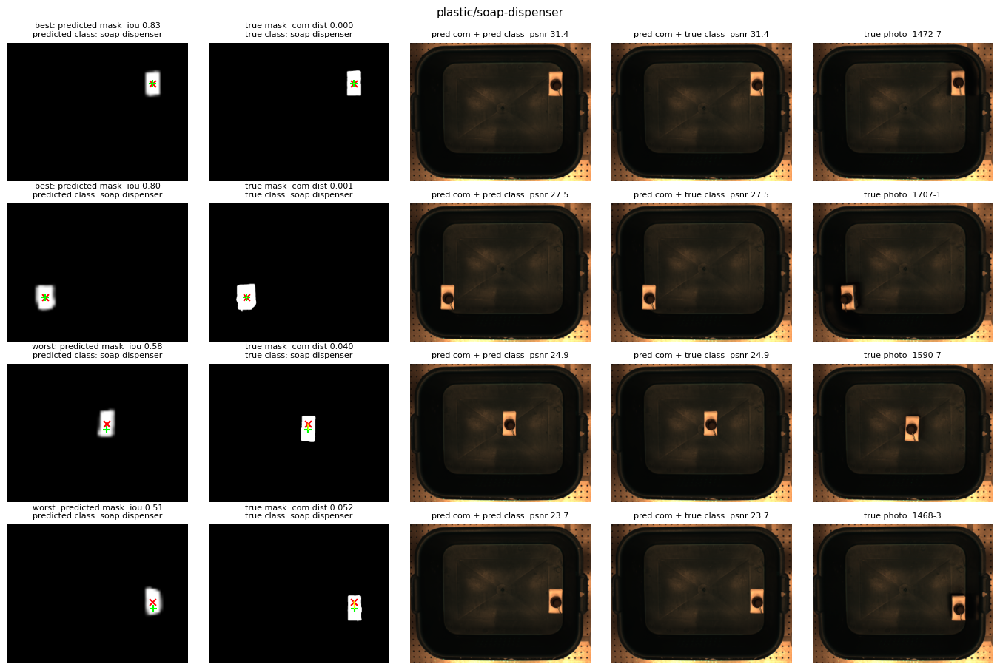

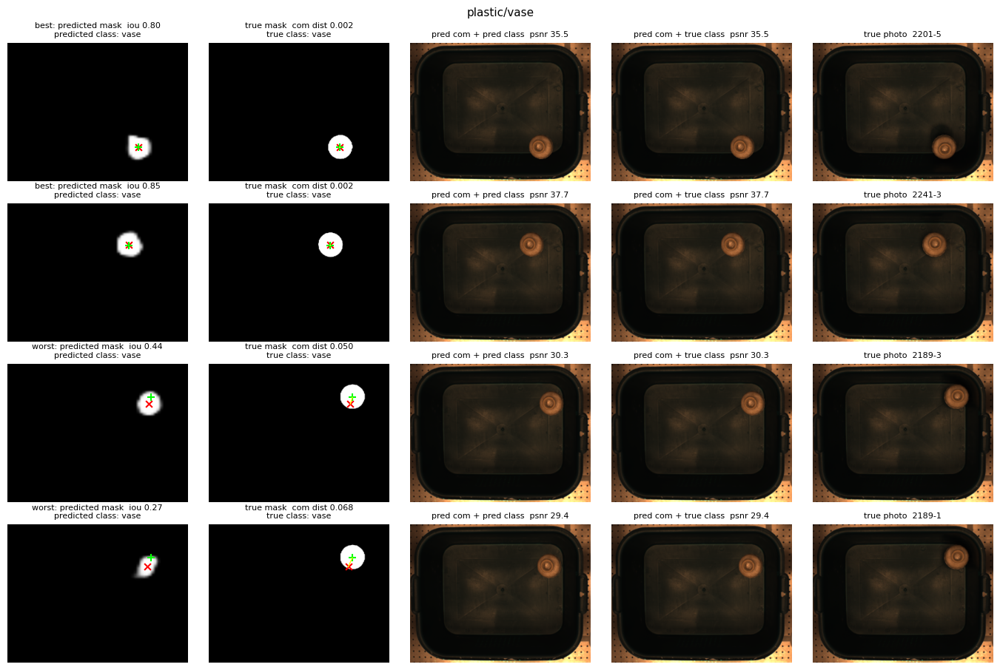

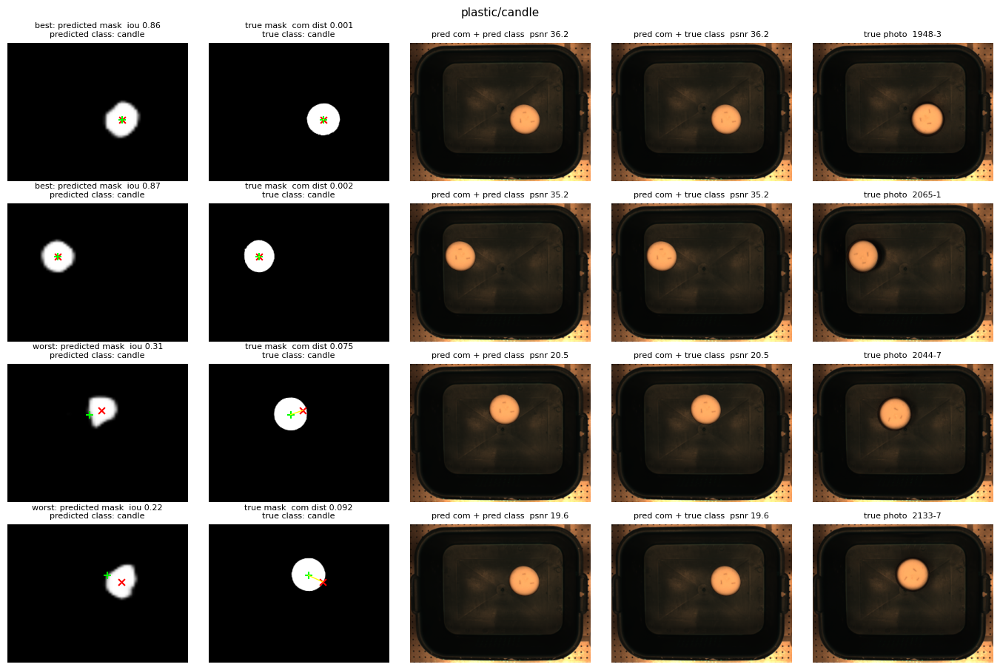

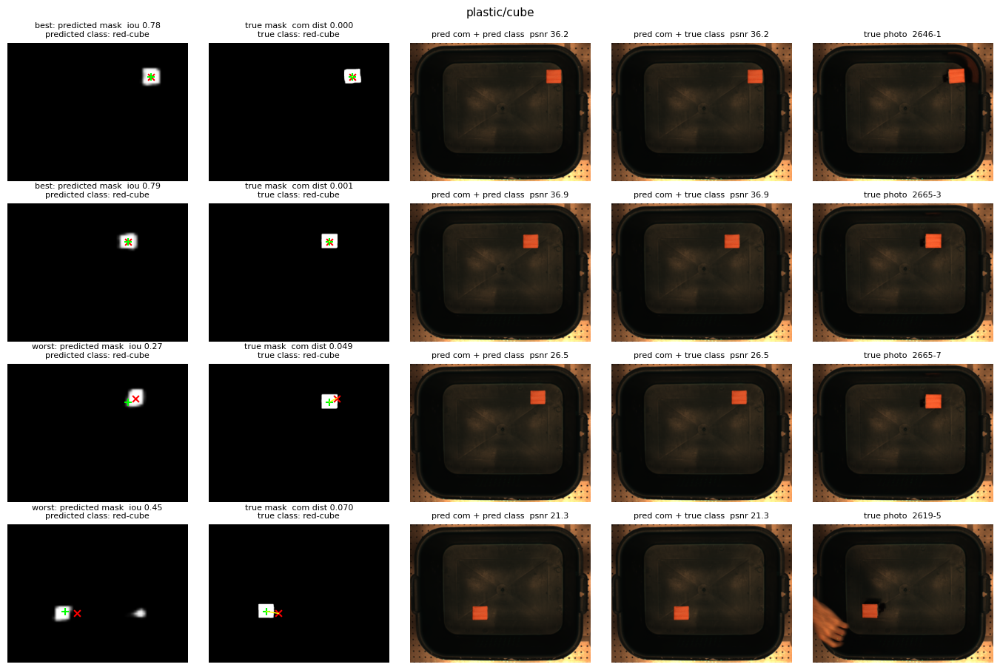

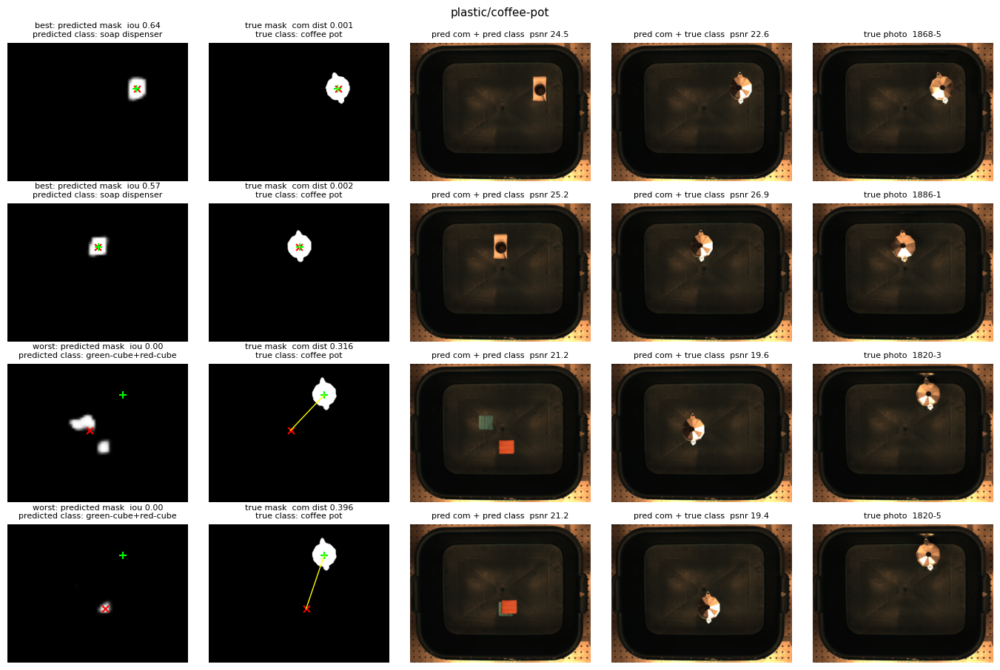

...

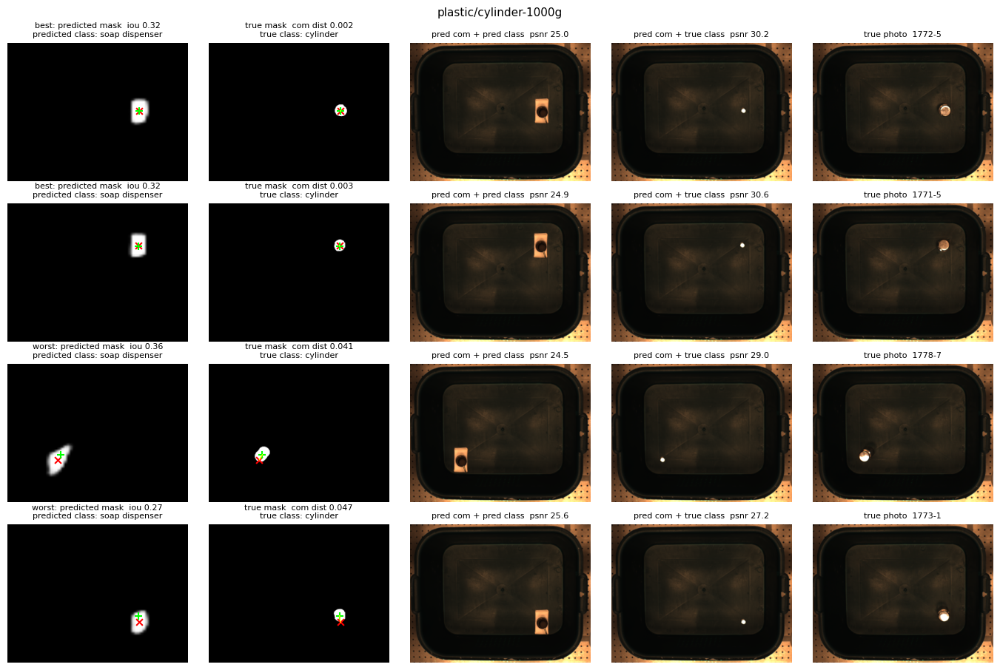

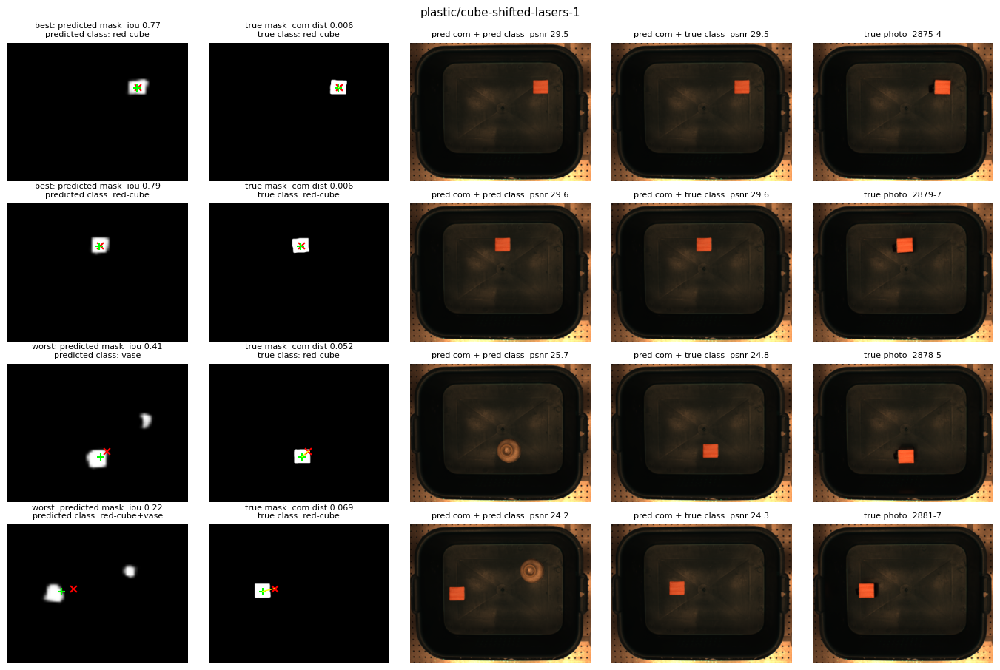

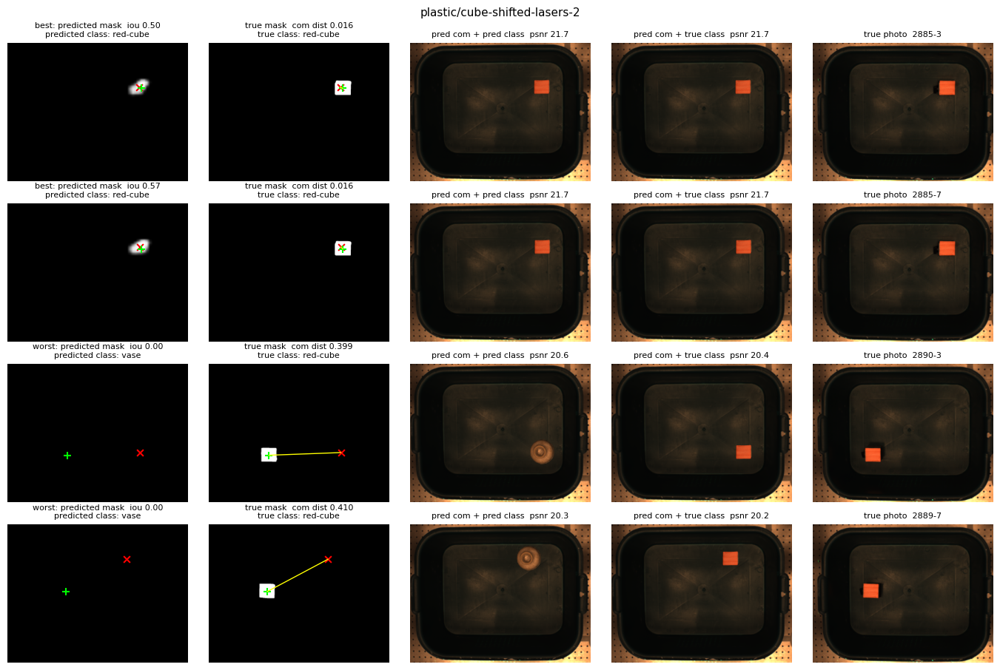

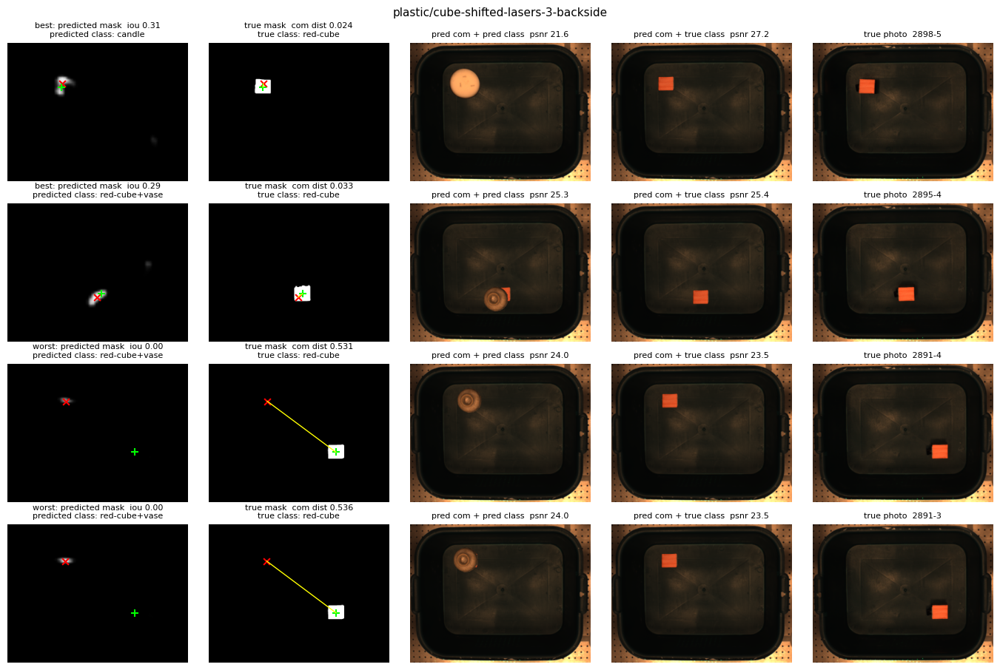

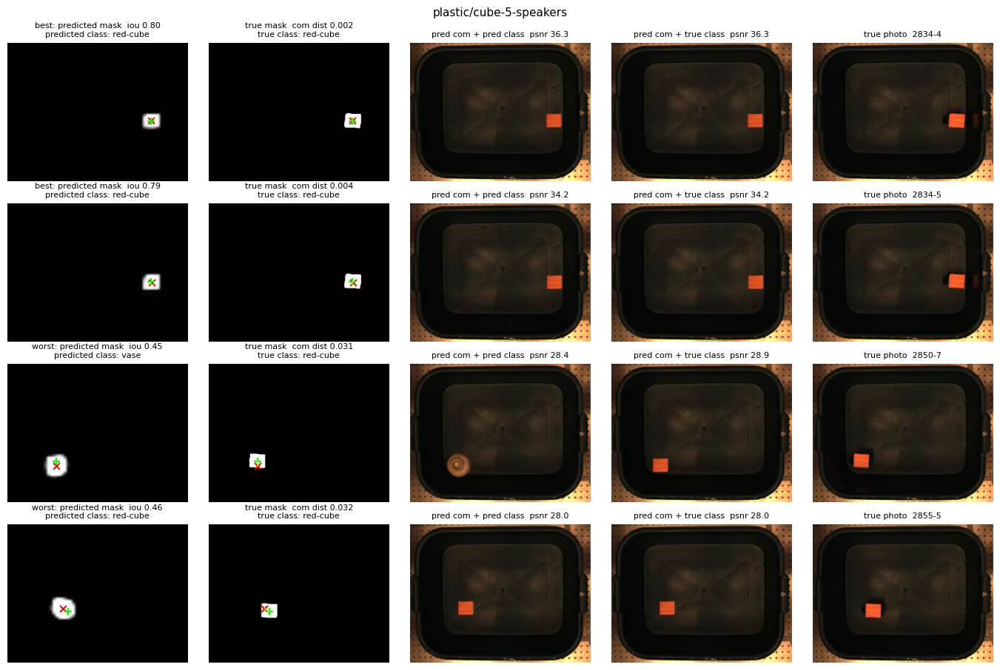

In [10]:
for split in EVAL: gallery(split, pred_class=True)